## Question 3

In [1]:
#import necessary libraries 
import re
import glob
import string
import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import nltk
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis
from gensim import corpora, models
from gensim.models import CoherenceModel
from collections import Counter
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from wordcloud import WordCloud

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('punkt_tab')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\jessb\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\jessb\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\jessb\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\jessb\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\jessb\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


##### Question 3.1

In [2]:
#Question 3.1
#unzipping research_corpus
zip_path = r"C:\Users\jessb\OneDrive\Desktop\University\University\CTI\Honours\Semester 2\ITNPA4\Assignment\Datasets\research_corpus.zip"
extract_folder = r"C:\Users\jessb\OneDrive\Desktop\University\University\CTI\Honours\Semester 2\ITNPA4\Assignment\Datasets\research_corpus"

with zipfile.ZipFile(zip_path) as z:
    z.extractall(extract_folder)

files = sorted(glob.glob(os.path.join(extract_folder, "**", "*.txt"), recursive=True),
               key=lambda f: int(re.findall(r"\d+", os.path.basename(f))[0]))
 
print(len(files), "files found")    

5 files found


In [3]:
#put articles in a df
articles = []
for file in files:
    with open(file, 'r', encoding='utf-8') as f:
        articles.append({"Article": os.path.basename(file).replace(".txt", ""), "content": f.read()})

df = pd.DataFrame(articles)
df["word_count"] = df["content"].str.split().str.len()
print(df.head()) 

      Article                                            content  word_count
0  research_1  The purposes of this article are to position m...        5602
1  research_2  Now I see it, now I don’t:\nresearcher’s posit...        2416
2  research_3  DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...        3828
3  research_4  Abstract\nCronbach’s alpha is a statistic comm...        5922
4  research_5  Denzin’s Paradigm Shift: Revisiting Triangulat...        4027


In [4]:
#beginnging of each article
for _, row in df.iterrows():
    print(row["Article"], ":", row["content"][:350].replace("\n", " "), "\n")

research_1 : The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods rese 

research_2 : Now I see it, now I don’t: researcher’s position and reflexivity in qualitative research Roni Berger Adelphi University, USA Abstract This article addresses potential effects on reflexivity of researcher’s social position (e.g. gender, age, race, immigration status, sexual orientation), personal experiences, and political and professional beliefs.  

research_3 : DEVELOPMENTAL RESEARCH: STUDIES OF INSTRUCTIONAL DESIGN AND DEVELOPMENT Rita C. Richey Wayne State University James D. Klein Arizona State University Wayne A. Nelson Southern Illinois University at Edwardsville 41.1 INTRODUCTION The field of instructional

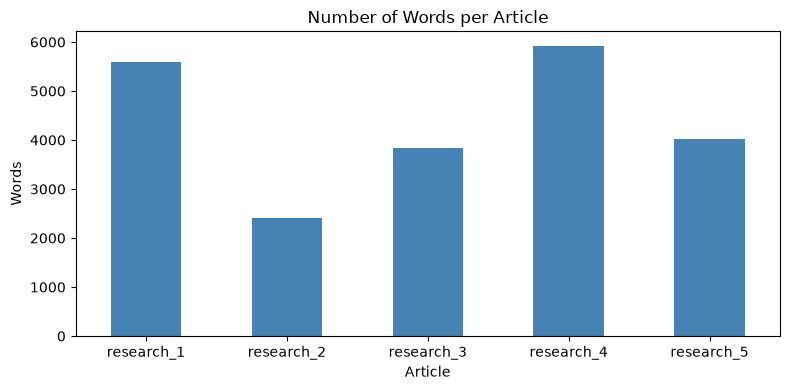

In [5]:
#visual of article lengths (ascedning order)
df.plot(x="Article", y="word_count", kind="bar", color="steelblue", legend=False, figsize=(8, 4))
plt.title("Number of Words per Article")
plt.xlabel("Article")
plt.ylabel("Words")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
 

##### Question 3.2

In [6]:
#checking for lines that appears more than once in the articles
for _, row in df.iterrows():
    lines = [l.strip() for l in row["content"].split("\n") if l.strip()]
    repeated = [l for l, c in Counter(lines).items() if c > 1]
    print(f"{row['Article']}: {len(lines)} lines, {len(repeated)} repeated lines")

research_1: 439 lines, 218 repeated lines
research_2: 176 lines, 0 repeated lines
research_3: 368 lines, 2 repeated lines
research_4: 70 lines, 0 repeated lines
research_5: 312 lines, 2 repeated lines


In [7]:
# are the first characers repeeated 
for _, row in df.iterrows():
   text = row["content"]
   position = text.find(text[:100], 1)
   print(f"{row['Article']}: start found again at character {position} of {len(text)}")

research_1: start found again at character 19080 of 38160
research_2: start found again at character -1 of 16104
research_3: start found again at character -1 of 26154
research_4: start found again at character -1 of 38950
research_5: start found again at character -1 of 26831


In [8]:
#lines that are short andcontain numbers or weird formats
for _, row in df.iterrows():
    lines = [l.strip() for l in row["content"].split("\n") if l.strip()]
    short = [l for l in lines if len(l.split()) <= 6 and (re.search(r"\d", l) or l.isupper())]
    print(row["Article"], ":", short[:12], "\n")

research_1 : ['major focus (Tashakkori & Teddlie, 1998).', '(Sieber, 1973, p. 1335).', 'OCTOBER 2004 15', '16 EDUCATIONAL RESEARCHER', 'major focus (Tashakkori & Teddlie, 1998).', '(Sieber, 1973, p. 1335).', 'OCTOBER 2004 15', '16 EDUCATIONAL RESEARCHER'] 

research_2 : ['468475QRJ0010.1177/1468794112468475Qualitative ResearchBerger', '2013', '220 Qualitative Research 15(2)', 'Berger 221', '(e.g. Valentine, 2007).', '2003).', 'and Kelly, 2002: paragraph 37).', '222 Qualitative Research 15(2)', '(Valentine, 2007).', '2002; Smith, 1999; Valentine, 2007).', 'Chaitin, 2006: 215).', 'Berger 223'] 

research_3 : ['DEVELOPMENTAL RESEARCH: STUDIES OF', 'INSTRUCTIONAL DESIGN AND DEVELOPMENT', '41.1 INTRODUCTION', '41.2 THE NATURE OF DEVELOPMENTAL', 'RESEARCH', '1099', '1100 • RICHEY, KLEIN, NELSON', '41.2.1 The Character of Development', '41.2.2 The Character of Research', '41. DEVELOPMENTAL RESEARCH • 1101', 'exemplified in particular cases. (p. 325)', '1991; Mishler, 1979).'] 

research_4 : [

In [9]:
# Find figure labels in every article and show the lines around them
for _, row in df.iterrows():
    lines = [l.strip() for l in row["content"].split("\n") if l.strip()]
    last_shown = -10
    for i, line in enumerate(lines):
        if re.match(r"(?i)fig(ure)?\.?\s*\d+$", line) and i > last_shown + 3:   # a line that is only a figure label
            print(row["Article"], "- line", i, ":", line)
            for l in lines[max(i - 2, 0): i + 5]:
                print(l[:100])
            print()
            last_shown = i

research_4 - line 38 : Fig. 1
Many, but not all, of the papers found to cite alpha values in the 2015 volumes of four science educ
A wide range of different qualitative descriptors was used by authors to interpret alpha values calc
Fig. 1
figure 1
Qualitative descriptors used for values/ranges of values of Cronbach’s alpha reported in papers in l
Full size image
The common notion of there being a threshold of acceptability for alpha values, if only as a rule of



In [10]:
#look for lines not actually part of the article such as title and author names
for _, row in df.iterrows():
    lines = [l.strip() for l in row["content"].split("\n") if l.strip()]
    print("=" * 30, row["Article"], "=" * 30)
    print("\n".join(lines[:30]), "\n")
 

============================== research_1 ==============================
The purposes of this article are to position mixed methods research
(mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism
as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting
mixed methods research. In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitative research, we explain the
tenets of pragmatism, we explain the fundamental principle of mixed
research and how to apply it, we provide specific sets of designs for
the two major types of mixed methods research (mixed-model designs and mixed-method designs), and, finally, we explain mixed methods research as following (recursively) an eight-step process. A key
feature of mixed methods research is its methodological pluralism

In [11]:
# Characters that are not standard English characters
other_chars = Counter(c for text in df["content"] for c in text if ord(c) > 127)
print(other_chars.most_common(20))

[('’', 169), ('“', 121), ('”', 120), ('‘', 27), ('–', 23), ('—', 23), ('…', 11), ('α', 6), ('•', 4), ('⇒', 4), ('©', 2), ('≤', 2), ('\ufeff', 2), ('à', 1), ('é', 1), ('≥', 1), ('á', 1), ('ó', 1), ('ä', 1), ('ï', 1)]


In [12]:
#find noise in text
noise_patterns = {
    "In-text citations": r"\([^()]*\d{4}[a-z]?[^()]*\)",
    "Page references": r"\(p+\.\s?\d+[^)]*\)",
    "Footnote numbers": r"(?<=[a-z][.,])\d+(?:,\s?\d+)*(?=\s)",
    "Emails": r"\S+@\S+",
    "Non-English characters": r"[^\x00-\x7f]",
}
noise_counts = pd.DataFrame({p: df["content"].str.count(pattern) for p, pattern in noise_patterns.items()})
noise_counts.index = df["Article"]
print(noise_counts)

            In-text citations  Page references  Footnote numbers  Emails  \
Article                                                                    
research_1                 58                0                 6       0   
research_2                 31                1                 0       1   
research_3                 49                8                 1       0   
research_4                 46               36                 0       0   
research_5                 95                5                 0       0   

            Non-English characters  
Article                             
research_1                      68  
research_2                      67  
research_3                      84  
research_4                     250  
research_5                      52  


In [13]:
#page headers, footers, and figure labels foound
header_patterns = [
    r"OCTOBER 2004 \d+", r"\d+ EDUCATIONAL RESEARCHER",
    r"\d+ Qualitative Research 15\(2\)", r"Berger \d+", r"\d+QRJ.*",
    r"\d+ • RICHEY, KLEIN, NELSON", r"41\. DEVELOPMENTAL RESEARCH • \d+",
    r"Fig\. \d+", r"figure \d+", r"Full size image",
    r"Fusch, Fusch, & Ness, 2018", r"Journal of Social Change \d+",
    r"\d{4}",
]

In [14]:
#remove noise and stuff
def remove_noise(text):
    #remove the second copy of the article in research_1
    second_copy = text.find(text[:100], 1)
    if second_copy > 0:
        text = text[:second_copy]
 
    #remove page headers, footers and web text
    lines = [l.strip() for l in text.split("\n") if l.strip()]
    lines = [l for l in lines if not any(re.fullmatch(p, l) for p in header_patterns)]

    #join the lines back together
    joined = []
    for i, line in enumerate(lines):
        next_line = lines[i + 1] if i + 1 < len(lines) else ""
        if len(line.split()) <= 10 and not line.endswith((".", ",", ";", ":", "?", "!")) and next_line[:1].isupper():
            line += "."
        joined.append(line)
    text = " ".join(joined)
 
    #remove contact details and website text
    text = re.sub(r"Corresponding author:.*?Email: \S+", " ", text)
    text = re.sub(r"Similar content being viewed by others.*?(?=Introduction)", " ", text)
 
    #remove citations, page references and footnote numbers
    text = re.sub(noise_patterns["In-text citations"], " ", text)
    text = re.sub(noise_patterns["Page references"], " ", text)
    text = re.sub(noise_patterns["Footnote numbers"], " ", text)
 
    #replace curly quotes and dashes with plain ones, and remove other non-English characters
    text = text.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    text = text.replace("–", "-").replace("—", "-")
    text = re.sub(r"[^\x00-\x7f]", " ", text)
 
    #sentence splitters treat every full stop as a possible sentence end
    text = text.replace("e.g.", "eg").replace("i.e.", "ie").replace("etc.", "etc")
    text = re.sub(r"\s+([.,;:])(?=\s|$)", r"\1", text)
    return re.sub(r"\s+", " ", text).strip()

In [15]:
#clean
df["clean_content"] = df["content"].apply(remove_noise)
df["clean_word_count"] = df["clean_content"].str.split().str.len()
df[["Article", "word_count", "clean_word_count"]]

,Article,word_count,clean_word_count
0,research_1,5602,2624
1,research_2,2416,2210
2,research_3,3828,3657
3,research_4,5922,5678
4,research_5,4027,3637


In [16]:
#check noise is gone
check = pd.DataFrame({p: df["clean_content"].str.count(pattern) for p, pattern in noise_patterns.items()})
check.index = df["Article"]
print(check)

            In-text citations  Page references  Footnote numbers  Emails  \
Article                                                                    
research_1                  0                0                 0       0   
research_2                  0                0                 0       0   
research_3                  0                0                 0       0   
research_4                  0                0                 0       0   
research_5                  0                0                 0       0   

            Non-English characters  
Article                             
research_1                       0  
research_2                       0  
research_3                       0  
research_4                       0  
research_5                       0  


In [17]:
#clean text
def clean_text(text):
    text = text.lower()
    text = text.replace("-", " ")
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text


def preprocess_text(text):
    tokens = nltk.word_tokenize(text)
    tokens = [word for word in tokens if word not in stop_words and len(word) > 2]
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return tokens

In [18]:
df["tokens"] = df["clean_content"].apply(clean_text).apply(preprocess_text)

In [19]:
#most commmon words in corpus
all_tokens = [word for tokens in df["tokens"] for word in tokens]
common_words = pd.DataFrame(Counter(all_tokens).most_common(25), columns=["word", "count"])
common_words["articles_containing"] = common_words["word"].apply(
    lambda w: sum(w in tokens for tokens in df["tokens"]))
print(common_words)

             word  count  articles_containing
0        research    306                    5
1           study    139                    5
2           alpha    118                    2
3      researcher    114                    5
4            data    109                    5
5             one     98                    5
6          method     96                    4
7     development     91                    3
8          design     87                    3
9   triangulation     83                    3
10    qualitative     81                    5
11          value     74                    5
12     instrument     68                    3
13        process     67                    5
14        science     59                    4
15      knowledge     58                    5
16            use     56                    5
17    reliability     56                    2
18          mixed     49                    2
19      cronbachs     49                    1
20        example     47          

In [20]:
#updatwe and remove stopwords
stop_words.update(["one", "use", "used", "may", "example"])
 
df["tokens"] = df["clean_content"].apply(clean_text).apply(preprocess_text)
df["token_count"] = df["tokens"].str.len()

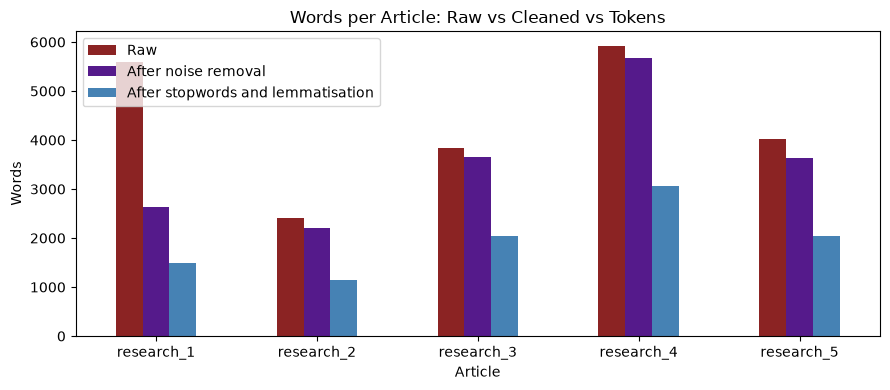

In [21]:
#visual
df.set_index("Article")[["word_count", "clean_word_count", "token_count"]].plot(
    kind="bar", color=["#8b2323", "#551a8b", "#4682b4"], figsize=(9, 4))
plt.title("Words per Article: Raw vs Cleaned vs Tokens")
plt.ylabel("Words")
plt.xticks(rotation=0)
plt.legend(["Raw", "After noise removal", "After stopwords and lemmatisation"])
plt.tight_layout()
plt.show()

In [22]:
#save clesaned corpus
df[["Article", "clean_content", "tokens"]].to_csv("research_corpus_clean.csv", index=False)

##### Question 3.3

In [23]:
article_1 = df.loc[0, "clean_content"]
sentences = nltk.sent_tokenize(article_1)
print("Sentences in article 1:", len(sentences))

Sentences in article 1: 88


In [24]:
# Word frequencies (stopwords removed)
word_freq = Counter(df.loc[0, "tokens"])
max_freq = max(word_freq.values())
word_freq = {word: count / max_freq for word, count in word_freq.items()}

In [25]:
# Score each sentence by adding up the frequencies of its words, very long sentences are skipped
sentence_scores = {}
for i, sentence in enumerate(sentences):
    if len(sentence.split()) <= 50:
        words = preprocess_text(clean_text(sentence))
        sentence_scores[i] = sum(word_freq.get(word, 0) for word in words)

In [26]:
#5 highest-scoring sentences
ranked = sorted(sentence_scores, key=sentence_scores.get, reverse=True)
top_sentences = sorted(ranked[:5])
summary_1 = " ".join(sentences[i] for i in top_sentences)

In [27]:
#summary article 1
print("Summary of Article 1:\n")
for i in top_sentences:
    print("-", sentences[i])
print(f"\nOriginal: {len(article_1.split())} words  ->  Summary: {len(summary_1.split())} words")

Summary of Article 1:

- We hope the field will move beyond quantitative versus qualitative research arguments because, as recognized by mixed methods research, both quantitative and qualitative research are important and useful.
- If you visualize a continuum with qualitative research anchored at one pole and quantitative research anchored at the other, mixed methods research covers the large set of points in the middle area.
- If one prefers to think categorically, mixed methods research sits in a new third chair, with qualitative research sitting on the left side and quantitative research sitting on the right side.
- Mixed methods research as the third research paradigm can also help bridge the schism between quantitative and qualitative research.
- Although many research procedures or methods typically have been linked to certain paradigms, this linkage between research paradigm and research methods is neither sacrosanct nor necessary.

Original: 2624 words  ->  Summary: 136 words


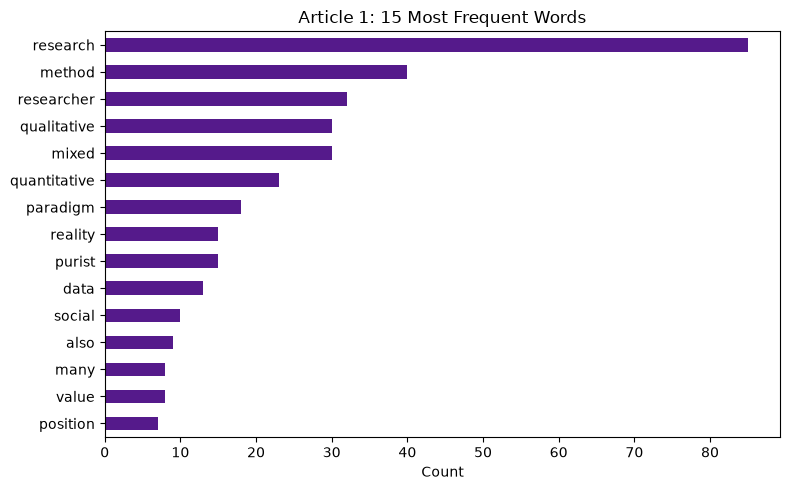

In [28]:
# Most frequent words in article 1
top_words = pd.Series(Counter(df.loc[0, "tokens"])).nlargest(15).sort_values()
top_words.plot(kind="barh", color="#551a8b", figsize=(8, 5))
plt.title("Article 1: 15 Most Frequent Words")
plt.xlabel("Count")
plt.tight_layout()
plt.show()

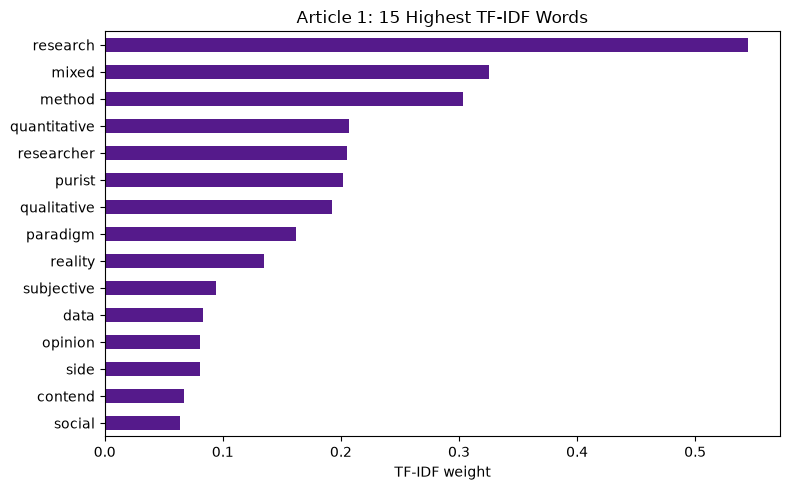

In [29]:
# Top TF-IDF words in article 1, using all 5 articles as the corpus
tfidf_all = TfidfVectorizer()
all_matrix = tfidf_all.fit_transform(df["tokens"].apply(" ".join))
article1_tfidf = pd.Series(all_matrix[0].toarray()[0], index=tfidf_all.get_feature_names_out())
article1_tfidf.nlargest(15).sort_values().plot(kind="barh", color="#551a8b", figsize=(8, 5))
plt.title("Article 1: 15 Highest TF-IDF Words")
plt.xlabel("TF-IDF weight")
plt.tight_layout()
plt.show()

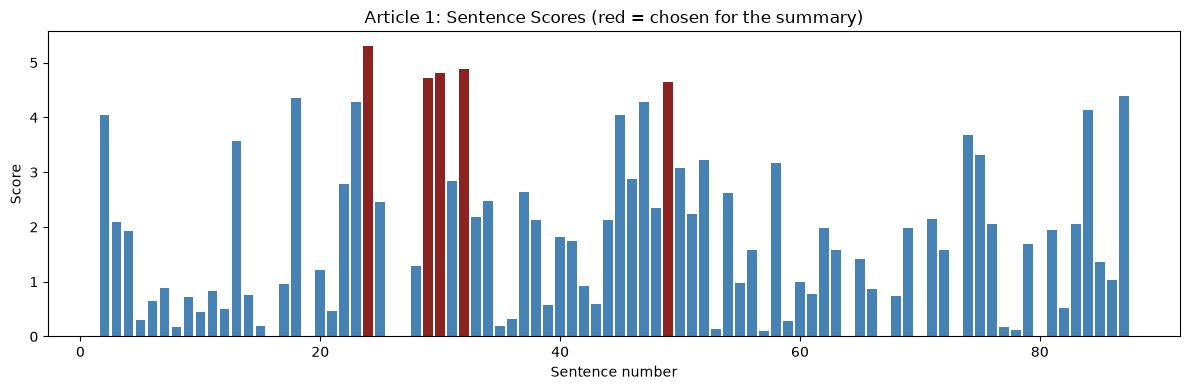

In [30]:
# Score of every sentence
scores = pd.Series(sentence_scores)
colours = ["#8b2323" if i in top_sentences else "#4682b4" for i in scores.index]
plt.figure(figsize=(12, 4))
plt.bar(scores.index, scores.values, color=colours)
plt.title("Article 1: Sentence Scores (red = chosen for the summary)")
plt.xlabel("Sentence number")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

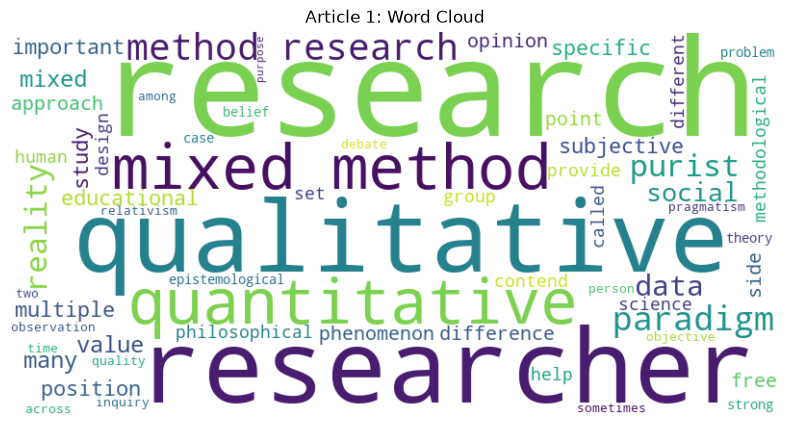

In [31]:
# Word cloud of article 1
wc = WordCloud(width=800, height=400, background_color="white", colormap="viridis", max_words=60)
wc.generate(" ".join(df.loc[0, "tokens"]))
plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Article 1: Word Cloud")
plt.show()

##### Question 3.4

In [32]:
# Split articles 2-5 into sentences
rows = []
for _, row in df.iloc[1:].iterrows():
    for position, sentence in enumerate(nltk.sent_tokenize(row["clean_content"])):
        # skip headings, keyword lists (seen at the start of some articles) and very long sentences
        if 10 <= len(sentence.split()) <= 50 and not sentence.startswith("Keywords"):
            rows.append({"Article": row["Article"], "position": position, "sentence": sentence})
 
sent_df = pd.DataFrame(rows)
sent_df["processed"] = sent_df["sentence"].apply(lambda s: " ".join(preprocess_text(clean_text(s))))
print("Sentences used:", len(sent_df))
sent_df["Article"].value_counts().sort_index()

Sentences used: 498


Article
research_2     44
research_3    151
research_4    158
research_5    145
Name: count, dtype: int64

In [33]:
# TF-IDF vectors
tfidf_matrix = TfidfVectorizer().fit_transform(sent_df["processed"])
similarity = cosine_similarity(tfidf_matrix)
np.fill_diagonal(similarity, 0)
 
graph = nx.from_numpy_array(similarity)
sent_df["score"] = pd.Series(nx.pagerank(graph))

In [34]:
# Top 2 sentences per article
ranked = sent_df.sort_values("score", ascending=False)
summary_df = ranked.groupby("Article").head(2)
summary_df = summary_df.sort_values(["Article", "position"])
 
print("Aggregate summary of articles 2-5:\n")
for _, row in summary_df.iterrows():
    print(f"[{row['Article']}] {row['sentence']}\n")

Aggregate summary of articles 2-5:

[research_2] One goal of reflexivity in qualitative research is to monitor such effects and thus enhance the accuracy of the research and 'the credibility of the findings by accounting for researcher values, beliefs, knowledge, and biases', that is, to gain plausibility by securing research's trustworthiness.

[research_2] Reflexivity is crucial throughout all phases of the research process, including the formulation of a research question, collection and analysis of data, and drawing conclusions.

[research_3] While instructional development typically builds on previous research, developmental research attempts to produce the models and principles that guide the design, development, and evaluation processes.

[research_3] Study of design, development, or evaluation processes, tools, or models.

[research_4] It is common to see the reliability of instruments used in published science education studies framed in terms of a statistic known as Cronbach'

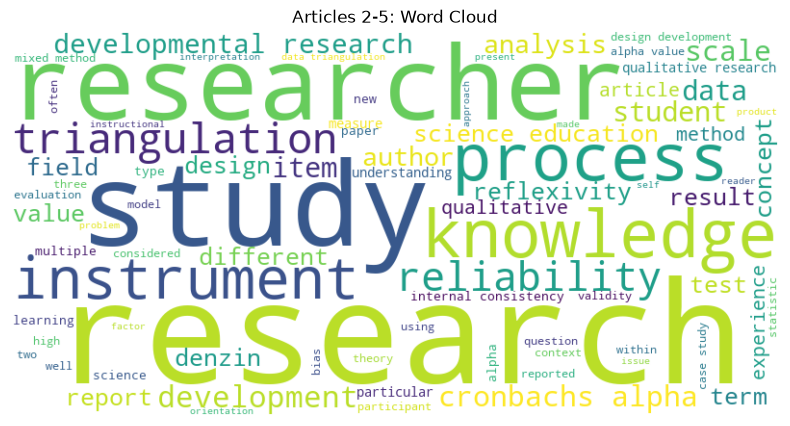

In [35]:
# Word cloud of articles 2-5 together
remaining_tokens = [word for tokens in df["tokens"].iloc[1:] for word in tokens]
wc = WordCloud(width=800, height=400, background_color="white", colormap="viridis", max_words=80)
wc.generate(" ".join(remaining_tokens))
plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Articles 2-5: Word Cloud")
plt.show()

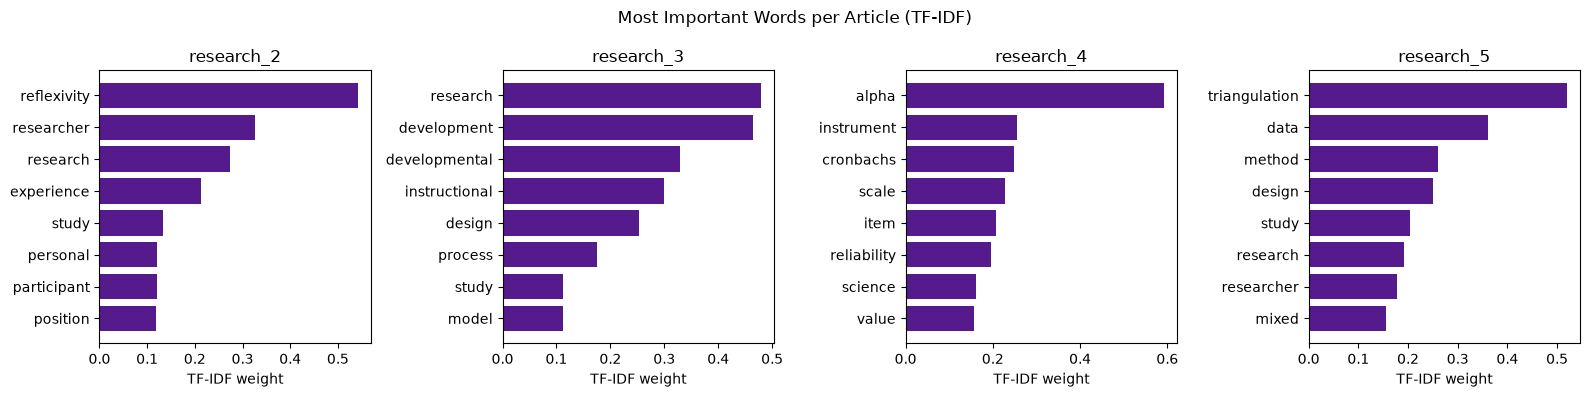

In [36]:
# Top 8 TF-IDF words of each article
tfidf_docs = TfidfVectorizer()
doc_matrix = tfidf_docs.fit_transform(df["tokens"].iloc[1:].apply(" ".join))
terms = tfidf_docs.get_feature_names_out()
 
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (i, article) in zip(axes, enumerate(df["Article"].iloc[1:])):
    weights = pd.Series(doc_matrix[i].toarray()[0], index=terms).nlargest(8).sort_values()
    ax.barh(weights.index, weights.values, color="#551a8b")
    ax.set_title(article)
    ax.set_xlabel("TF-IDF weight")
plt.suptitle("Most Important Words per Article (TF-IDF)")
plt.tight_layout()
plt.show()

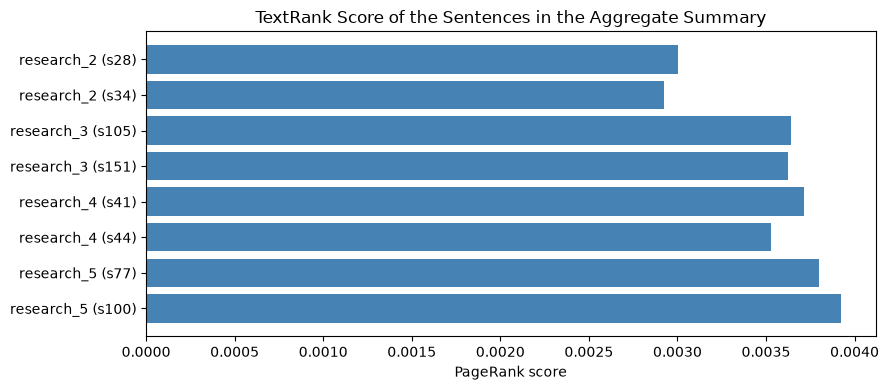

In [37]:
# TextRank scores of the chosen sentences
labels = [f"{a} (s{p})" for a, p in zip(summary_df["Article"], summary_df["position"])]
plt.figure(figsize=(9, 4))
plt.barh(labels[::-1], summary_df["score"].values[::-1], color="#4682b4")
plt.title("TextRank Score of the Sentences in the Aggregate Summary")
plt.xlabel("PageRank score")
plt.tight_layout()
plt.show()

## Question 4

##### Question 4.1

In [38]:
# Split each article's tokens into passages of 100 words
passages = []
for _, row in df.iterrows():
    tokens = row["tokens"]
    for start in range(0, len(tokens), 100):
        passage = tokens[start:start + 100]
        if len(passage) >= 50:                         # skip a very short last passage
            passages.append({"article": row["Article"], "tokens": passage})
 
passages_df = pd.DataFrame(passages)
print("Number of passages:", len(passages_df))
passages_df["article"].value_counts().sort_index()

Number of passages: 99


article
research_1    15
research_2    12
research_3    21
research_4    31
research_5    20
Name: count, dtype: int64

In [39]:
# Build dictionary and filter out words
dictionary = corpora.Dictionary(passages_df["tokens"])
print("Length of the Dictionary before filtering:", len(dictionary))
dictionary.filter_extremes(no_below=3, no_above=0.5)
print("Length of the Dictionary after filtering:", len(dictionary))

Length of the Dictionary before filtering: 2450
Length of the Dictionary after filtering: 718


In [40]:
# frequency BOW
corpus_bow = [dictionary.doc2bow(tokens) for tokens in passages_df["tokens"]]
print(f"Corpus size: {len(corpus_bow)} documents")

Corpus size: 99 documents


In [41]:
# Search for optimal number of topics using coherence
topic_range = range(2, 11)
coherence_scores = []
 
for k in topic_range:
    lda_tmp = models.LdaModel(corpus=corpus_bow, num_topics=k, id2word=dictionary,
                              passes=20, alpha='auto', eta='auto', random_state=42)
    cm = CoherenceModel(model=lda_tmp, texts=passages_df["tokens"].tolist(),
                        dictionary=dictionary, coherence='c_v', processes=1)
    score = cm.get_coherence()
    coherence_scores.append(score)
    print(f"k={k:2d}  :  Coherence={score:.4f}")

k= 2  :  Coherence=0.4729
k= 3  :  Coherence=0.6991
k= 4  :  Coherence=0.7517
k= 5  :  Coherence=0.7417
k= 6  :  Coherence=0.6676
k= 7  :  Coherence=0.6330
k= 8  :  Coherence=0.5905
k= 9  :  Coherence=0.6170
k=10  :  Coherence=0.5950


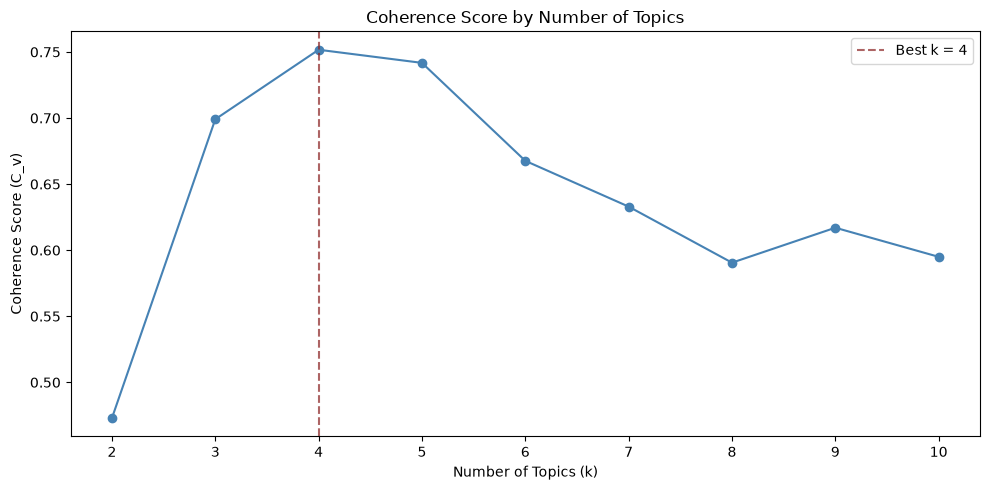

Best number of topics: k = 4 (coherence = 0.7517)


In [42]:
# Plot coherence scores
plt.figure(figsize=(10, 5))
plt.plot(list(topic_range), coherence_scores, "o-", color="#4682b4")
best_k = list(topic_range)[np.argmax(coherence_scores)]
plt.axvline(x=best_k, ls="--", color="#8b2323", alpha=0.7, label=f"Best k = {best_k}")
plt.xlabel("Number of Topics (k)")
plt.ylabel("Coherence Score (C_v)")
plt.title("Coherence Score by Number of Topics")
plt.legend()
plt.tight_layout()
plt.show()
 
print(f"Best number of topics: k = {best_k} (coherence = {max(coherence_scores):.4f})")

In [43]:
# Train the final model with the best k
lda_model = models.LdaModel(corpus=corpus_bow, num_topics=best_k, id2word=dictionary,
                            passes=20, alpha='auto', eta='auto', random_state=42)
lda_model.print_topics(num_words=10)

[(0,
  '0.049*"development" + 0.029*"process" + 0.027*"developmental" + 0.027*"design" + 0.025*"instructional" + 0.016*"evaluation" + 0.015*"type" + 0.012*"model" + 0.011*"product" + 0.011*"knowledge"'),
 (1,
  '0.034*"researcher" + 0.032*"data" + 0.028*"method" + 0.025*"triangulation" + 0.023*"qualitative" + 0.015*"mixed" + 0.013*"design" + 0.010*"multiple" + 0.010*"reflexivity" + 0.010*"quantitative"'),
 (2,
  '0.051*"alpha" + 0.025*"value" + 0.022*"cronbachs" + 0.021*"reliability" + 0.019*"instrument" + 0.015*"statistic" + 0.014*"item" + 0.014*"internal" + 0.013*"paper" + 0.013*"science"'),
 (3,
  '0.029*"instrument" + 0.028*"scale" + 0.028*"science" + 0.028*"alpha" + 0.018*"value" + 0.017*"item" + 0.015*"knowledge" + 0.015*"report" + 0.014*"measure" + 0.013*"test"')]

In [44]:
# Evaluate the final model
print(f"Perplexity: {lda_model.log_perplexity(corpus_bow):.4f}")
coherence_final = CoherenceModel(model=lda_model, texts=passages_df["tokens"].tolist(),
                                 dictionary=dictionary, coherence='c_v', processes=1)
print(f"Coherence Score: {coherence_final.get_coherence():.4f}")

Perplexity: -5.9605
Coherence Score: 0.7517


In [45]:
# Topic list: top 10 words of each topic
topic_words = pd.DataFrame({f"Topic {i}": [word for word, _ in lda_model.show_topic(i, topn=10)]
                            for i in range(best_k)})
print("Top 10 words for each topic:\n")
print(topic_words)

Top 10 words for each topic:

         Topic 0        Topic 1      Topic 2     Topic 3
0    development     researcher        alpha  instrument
1        process           data        value       scale
2  developmental         method    cronbachs     science
3         design  triangulation  reliability       alpha
4  instructional    qualitative   instrument       value
5     evaluation          mixed    statistic        item
6           type         design         item   knowledge
7          model       multiple     internal      report
8        product    reflexivity        paper     measure
9      knowledge   quantitative      science        test


In [46]:
# Topic distribution of every passage
rows_list = []
for bow in corpus_bow:
    rows_list.append(dict(lda_model.get_document_topics(bow, minimum_probability=0)))
topic_dist = pd.DataFrame(rows_list).fillna(0)

topic_dist.columns = [f"Topic {i}" for i in topic_dist.columns]
topic_dist["article"] = passages_df["article"]
article_topics = topic_dist.groupby("article").mean()
article_topics.round(2)

,Topic 0,Topic 1,Topic 2,Topic 3
article,,,,
research_1,0.03,0.91,0.02,0.04
research_2,0.01,0.98,0.01,0.00
research_3,0.96,0.01,0.00,0.02
research_4,0.00,0.00,0.64,0.36
research_5,0.00,1.00,0.00,0.00


In [47]:
# Dominant topic of each passage
passages_df["dominant_topic"] = topic_dist.drop(columns="article").values.argmax(axis=1)
print("Passages per dominant topic:")
print(passages_df["dominant_topic"].value_counts().sort_index())

Passages per dominant topic:
dominant_topic
0    21
1    47
2    20
3    11
Name: count, dtype: int64


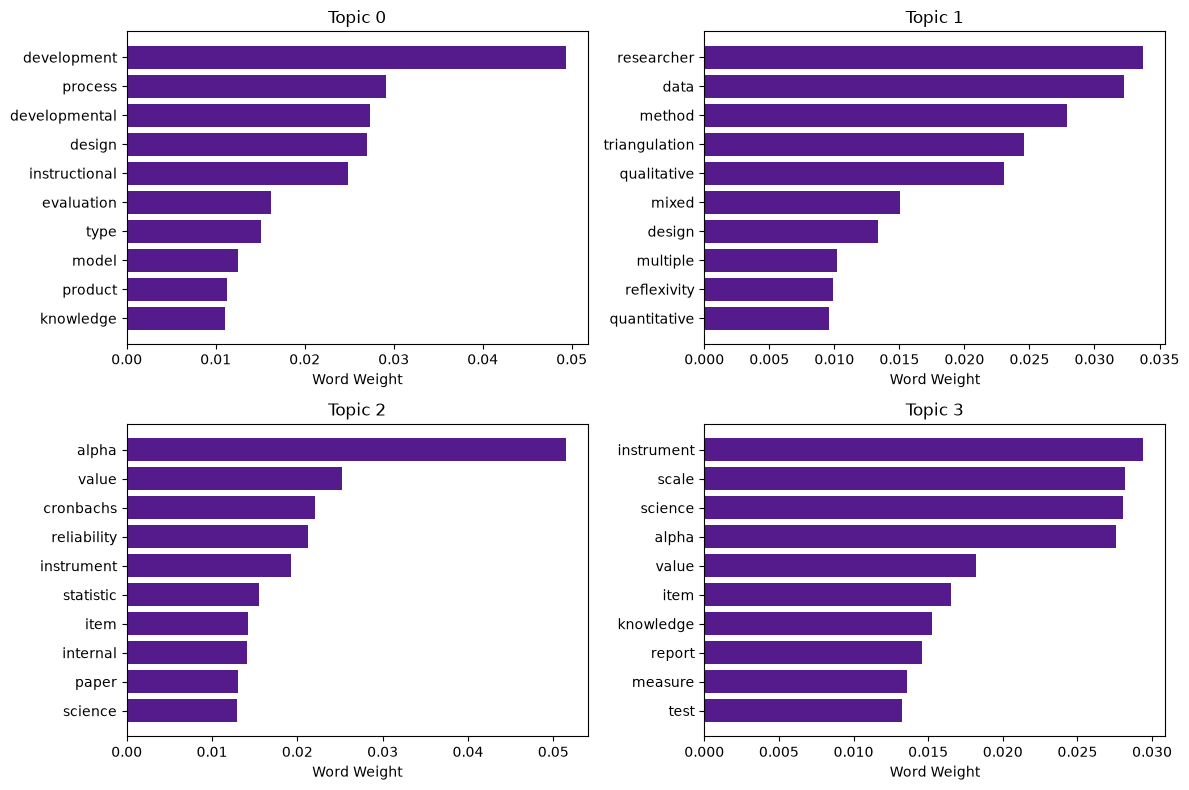

In [48]:
# Top 10 words and their weights for each topic
cols = 2
n_rows = int(np.ceil(best_k / cols))
fig, axes = plt.subplots(n_rows, cols, figsize=(6 * cols, 4 * n_rows))
axes = axes.flatten()
 
for i in range(best_k):
    words, weights = zip(*lda_model.show_topic(i, topn=10))
    axes[i].barh(words[::-1], weights[::-1], color="#551a8b")
    axes[i].set_title(f"Topic {i}")
    axes[i].set_xlabel("Word Weight")
 
for j in range(best_k, len(axes)):
    axes[j].axis("off")
 
plt.tight_layout()
plt.show()

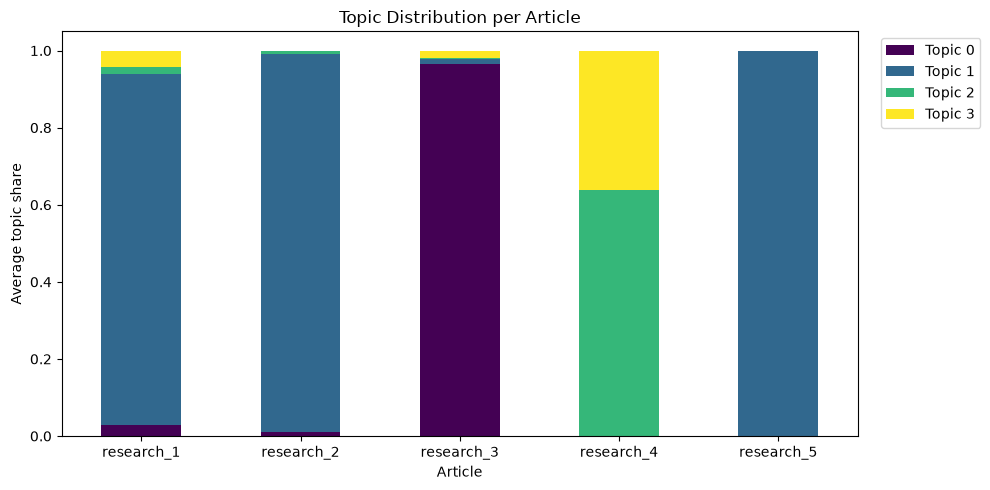

In [49]:
# Topic distribution per article
article_topics.plot(kind="bar", stacked=True, figsize=(10, 5), colormap="viridis")
plt.title("Topic Distribution per Article")
plt.xlabel("Article")
plt.ylabel("Average topic share")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

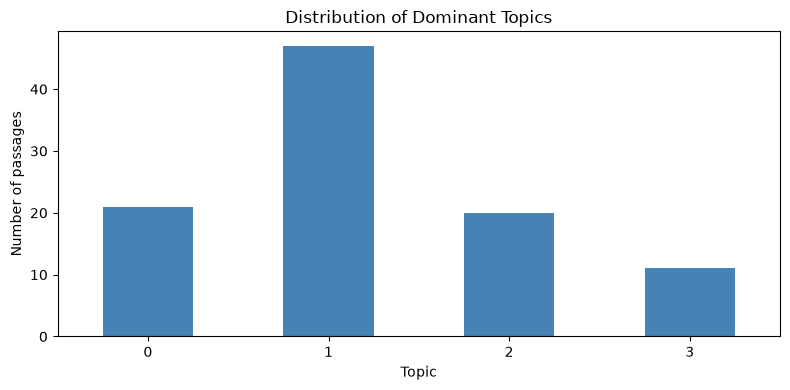

In [50]:
# Number of passages per dominant topic
passages_df["dominant_topic"].value_counts().sort_index().plot(kind="bar", color="#4682b4", figsize=(8, 4))
plt.title("Distribution of Dominant Topics")
plt.xlabel("Topic")
plt.ylabel("Number of passages")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

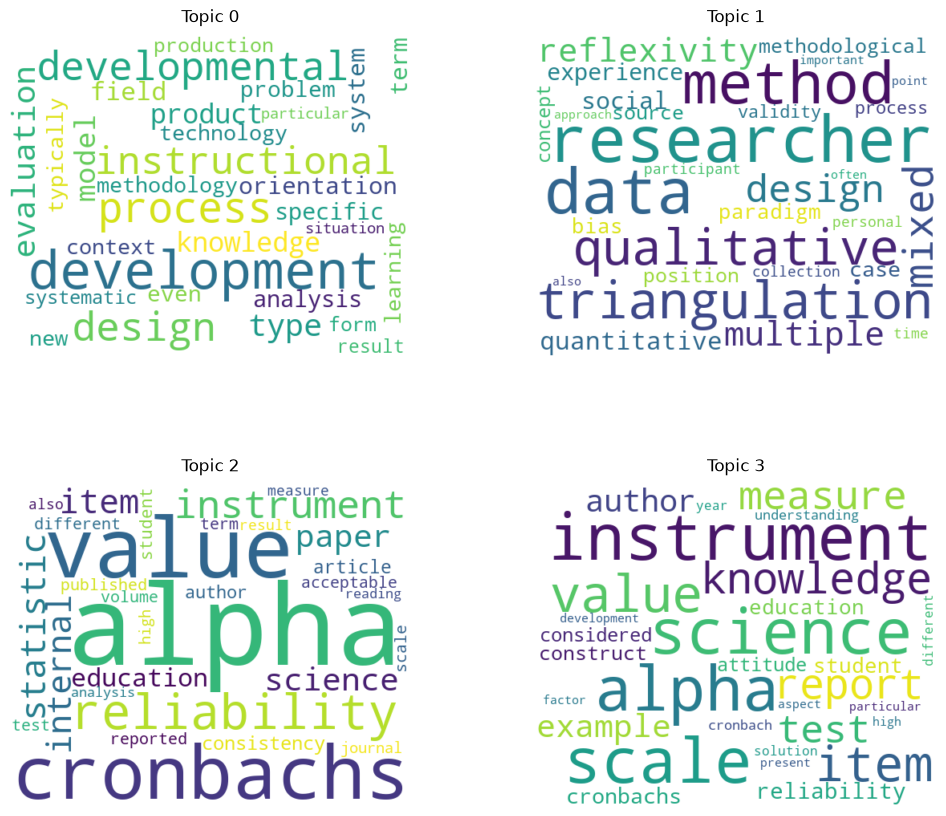

In [51]:
# Word clouds for each topic
fig, axes = plt.subplots(n_rows, cols, figsize=(6 * cols, 5 * n_rows))
axes = axes.flatten()
 
for i in range(best_k):
    word_weights = dict(lda_model.show_topic(i, topn=30))
    wc = WordCloud(width=500, height=400, background_color="white", colormap="viridis", max_words=30)
    wc.generate_from_frequencies(word_weights)
    axes[i].imshow(wc, interpolation="bilinear")
    axes[i].set_title(f"Topic {i}", fontsize=12, pad=10)
    axes[i].axis("off")
 
for j in range(best_k, len(axes)):
    axes[j].axis("off")
 
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.show()

##### Question 4.2

In [52]:
# pyLDAvis
pyLDAvis.enable_notebook()
vis = gensimvis.prepare(lda_model, corpus_bow, dictionary, sort_topics=False, mds="mmds")
pyLDAvis.save_html(vis, "lda_intertopic_map.html")      # also save the map as a web page
pyLDAvis.display(vis)

c:\Users\jessb\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\manifold\_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
c:\Users\jessb\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\manifold\_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(
